## EDA

#### Columns by business question

| Sub-question | Table | Columns |
|---|---|---|
| **1a** Campaign profile | `campaigns_clean` | `CAMPAIGN`, `DESCRIPTION`, `START_DAY`, `END_DAY`, eligibility flags |
| | `hh_campaign` | `household_key`, `CAMPAIGN`, `DESCRIPTION` (reach by type) |
| | `coupons_clean` + `products` | `COUPON_UPC`, `PRODUCT_ID`, `DEPARTMENT`, `COMMODITY_DESC` (coupon count, categories) |
| **1b** Spending lift | `transactions_clean` | `household_key`, `BASKET_ID`, `DAY`, `SALES_VALUE` |
| | `hh_campaign` | `household_key`, `CAMPAIGN`, `DESCRIPTION`, `has_overlap`, `n_concurrent` |
| | `campaigns_clean` | `CAMPAIGN`, `START_DAY`, `END_DAY`, `bq1_eligible` (window dates) |
| **1c** Who responds | `redemptions_clean` | `household_key`, `CAMPAIGN`, `COUPON_UPC`, `DAY` |
| | `demographics_clean` | `age_group`, `income_band`, `hh_size`, `homeowner`, `KID_CATEGORY_DESC` |
| **2a** Persistence | `transactions_clean` + `hh_campaign` + `campaigns_clean` | Same as 1b, post window, `bq2_eligible` |
| **2b** Repurchase | `redemptions_clean` + `coupons_clean` + `transactions_clean` | `COUPON_UPC`, `PRODUCT_ID`, `DAY`, `SALES_VALUE`, `RETAIL_DISC`, `COUPON_DISC` |
| **2c** Drop-off prediction | Built from all of the above | Household features + drop-off label |

*Not used: `QUANTITY` (unreliable, spend used instead), `STORE_ID`, `TRANS_TIME`, `WEEK_NO` (windows are in days), `SUB_COMMODITY_DESC`, `CURR_SIZE_OF_PRODUCT` (incomplete).*

In [22]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

CLEAN_DIR = Path.cwd().parent / "data" / "clean"
t           = pd.read_csv(CLEAN_DIR / "transactions_clean.csv")
cd          = pd.read_csv(CLEAN_DIR / "campaigns_clean.csv")
hh_campaign = pd.read_csv(CLEAN_DIR / "hh_campaign.csv")
redemptions = pd.read_csv(CLEAN_DIR / "redemptions_clean.csv")
coupons     = pd.read_csv(CLEAN_DIR / "coupons_clean.csv")
demo        = pd.read_csv(CLEAN_DIR / "demographics_clean.csv")
products    = pd.read_csv(CLEAN_DIR / "products.csv")


#### Households and spend

         spend   trips  basket_size
count   2500.0  2500.0       2500.0
mean    2947.7   100.5         32.2
std     2961.7   104.8         20.2
min        8.2     1.0          2.4
25%      911.1    36.0         18.1
50%     2036.6    73.0         27.6
75%     4013.7   129.0         41.2
max    26210.8  1206.0        181.3


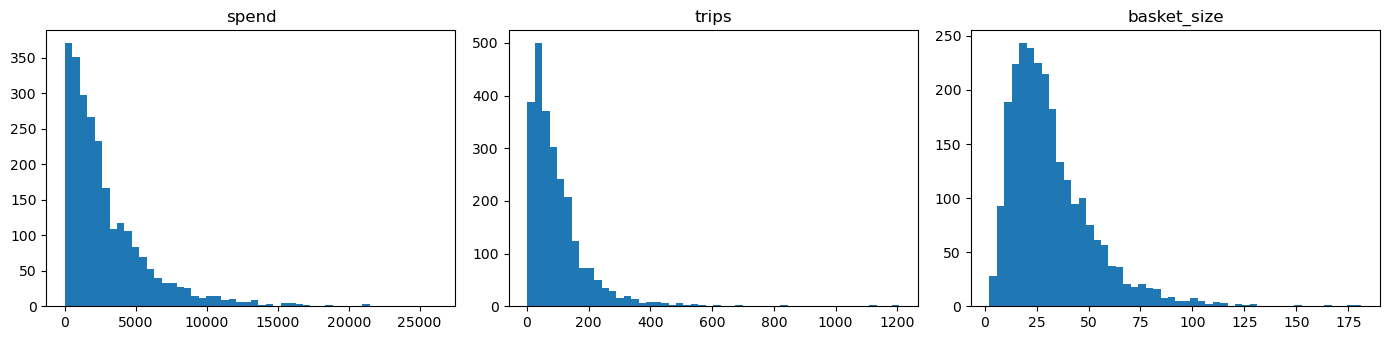

In [12]:
#Full period (2 years)

hh = t.groupby("household_key").agg(spend=("SALES_VALUE", "sum"),
                                    trips=("BASKET_ID", "nunique"))

hh["basket_size"] = hh["spend"] / hh["trips"]
print(hh.describe().round(1))

fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
for a, col in zip(ax, ["spend", "trips", "basket_size"]):
    a.hist(hh[col], bins=50); a.set_title(col)
plt.tight_layout()

In [13]:
top = hh.sort_values("trips", ascending=False).head(5)
print(top)

                  spend  trips  basket_size
household_key                              
1510            8623.20   1206     7.150249
2337           11597.76   1200     9.664800
1795            9397.52   1123     8.368228
900            13298.93   1117    11.905936
762             8109.65    855     9.484971


In [14]:
hh["high_freq"] = hh["trips"] > 800
print(hh["high_freq"].sum(), "high-frequency households")

8 high-frequency households


In [15]:
# Weekly figures - Stable window 
#  What does a typical household spend per week in the stable period weeks 17-100 (84 weeks) ?

win = t[(t["DAY"] >= 113) & (t["DAY"] <= 700)]
hh_w = win.groupby("household_key").agg(spend=("SALES_VALUE", "sum"),
                                         trips=("BASKET_ID", "nunique"))
hh_w["weekly_spend"] = hh_w["spend"] / 84
hh_w["weekly_trips"] = hh_w["trips"] / 84
hh_w["basket_size"]  = hh_w["spend"] / hh_w["trips"]
print(hh_w[["weekly_spend", "weekly_trips", "basket_size"]].describe().round(2))

       weekly_spend  weekly_trips  basket_size
count       2492.00       2492.00      2492.00
mean          31.80          1.08        32.37
std           32.64          1.16        20.77
min            0.05          0.01         2.36
25%            9.29          0.38        17.78
50%           21.80          0.77        27.37
75%           43.66          1.40        41.08
max          303.10         14.21       185.01


**Summary**
**Full period**
- Over the full period, the median household spent $2,037 (mean $2,948) across 73 trips. The middle half spent $911–$4,014.
- Basket size is stable across both views (median about $27.50), while trip counts vary widely (1 to 1,206), confirming frequency as the main driver of spend differences.
- Full-period totals understate households that joined during the ramp-up, so weekly figures from weeks 17–100 are used for comparisons.

Note: A handful of households make 850–1,200 trips (about 8–12 a week) with $7–$12 baskets, consistent with convenience-style shopping or shared cards. Kept as real behavior and flagged high_freq for robustness checks.

**Stable period: weekly view**
- Weekly spend is right-skewed: median $21.80 vs. mean $31.80, with the middle half at $9–$44 a week. Medians are used throughout.
- The typical household makes 0.77 trips a week (about 3 a month). A quarter shop fewer than once every 2–3 weeks.
- Households differ more in shopping frequency (about 3.7× spread) than in basket size (about 2.3×), so campaign lift is measured on trips and basket size separately.
- 8 households have no purchases in the stable window (weeks 17–100).
- Low-activity households make % lift unstable, so a minimum baseline activity rule will be set before 1b.



#### Campaigns 



In [16]:
cd["duration_days"] = cd["END_DAY"] - cd["START_DAY"] +1
reach = hh_campaign.groupby("CAMPAIGN")["household_key"].nunique().rename("households")
n_coupons = coupons.groupby("CAMPAIGN")["COUPON_UPC"].nunique().rename("coupons")

camp = cd.set_index("CAMPAIGN").join([reach, n_coupons])

print(camp.groupby("DESCRIPTION")[["duration_days", "households", "coupons"]].agg(["mean", "min", "max"]).round(0))

            duration_days          households            coupons          
                     mean min  max       mean  min   max    mean  min  max
DESCRIPTION                                                               
TypeA                48.0  41   56      796.0  332  1133   197.0  181  209
TypeB                39.0  33   62      140.0   13   276    16.0    2   33
TypeC                76.0  33  162       96.0   12   244    19.0    1   34


CAMPAIGN
1     268
2     224
3     214
4     169
5     179
6     138
7     120
8      94
9      62
10     50
11     24
12     26
13      7
14      4
15      3
16      1
17      1
Name: count, dtype: int64


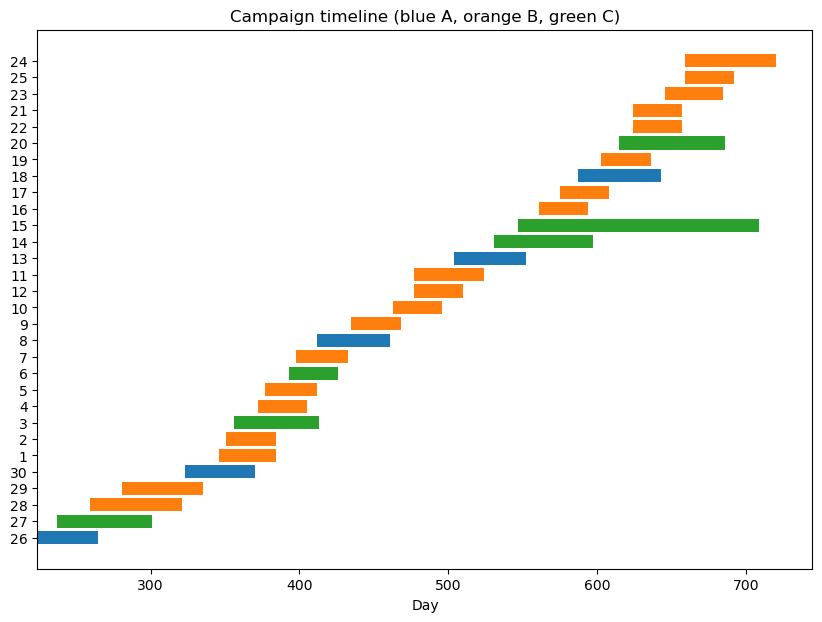

In [17]:
# Timeline chart
camp_sorted = camp.sort_values("START_DAY")
colors = {"TypeA": "tab:blue", "TypeB": "tab:orange", "TypeC": "tab:green"}
plt.figure(figsize=(10, 7))
plt.barh(camp_sorted.index.astype(str), camp_sorted["duration_days"],
         left=camp_sorted["START_DAY"], color=camp_sorted["DESCRIPTION"].map(colors))
plt.xlabel("Day"); plt.title("Campaign timeline (blue A, orange B, green C)")

# Campaigns per household
print(hh_campaign.groupby("household_key")["CAMPAIGN"].nunique().value_counts().sort_index())

**Timeline**
- TypeA campaigns are spaced out (about every 70–90 days), like regular broad promotions.
- TypeB campaigns cluster, especially around days 340–420 and 600–700, which is where most overlap comes from.
- Campaign 15 spans almost the whole second half (days 547–708), which confirms excluding it.

**Campaigns per household**
- 1,584 households received at least one campaign. The median household received 4.
- 268 received just 1, while 178 received 9 or more (up to 17).
- Effect: the same households show up across many campaigns, so their results aren't independent. Add “number of campaigns received” as a control variable in your regression (your mentor's ML suggestion).

In [18]:
# Exclude campaign 15
print(camp[camp.index != 15].groupby("DESCRIPTION")["duration_days"].agg(["mean", "median", "min", "max"]))


                  mean  median  min  max
DESCRIPTION                             
TypeA        48.200000    48.0   41   56
TypeB        38.631579    33.0   33   62
TypeC        58.200000    64.0   33   71


In [19]:
# Campaign B pattern
print(camp[(camp.index != 15) & (camp["DESCRIPTION"] == "TypeB")]["duration_days"].value_counts())

duration_days
33    11
35     2
61     1
39     1
47     1
38     1
54     1
62     1
Name: count, dtype: int64


- Excluding campaign 15, all campaigns run 33–71 days, and type ranges overlap.
- TypeB is mostly a standard 33-day format (median = minimum), TypeA runs a mid-length 41–56 days (median 48), and TypeC is mostly long (median 64).
- A duration grouping would largely mirror the types (B short, A medium, C long), so A/B/C is kept as the main grouping.


In [24]:
# Coupon categories by type: share of coupon products per department

cp = (coupons.merge(products[["PRODUCT_ID", "DEPARTMENT"]], on="PRODUCT_ID").merge(
    cd[["CAMPAIGN", 'DESCRIPTION']], on="CAMPAIGN"
))

cp = cp[cp["CAMPAIGN"] != 15]

print(pd.crosstab(cp["DEPARTMENT"], cp["DESCRIPTION"], normalize="columns")
        .sort_values("TypeB", ascending=False).head(8).round(2))

DESCRIPTION    TypeA  TypeB  TypeC
DEPARTMENT                        
GROCERY         0.37   0.67   0.47
DRUG GM         0.26   0.23   0.53
COSMETICS       0.06   0.05   0.00
NUTRITION       0.02   0.02   0.00
MEAT-PCKGD      0.07   0.01   0.00
SEAFOOD-PCKGD   0.02   0.01   0.00
PRODUCE         0.08   0.00   0.00
DELI            0.00   0.00   0.00


- Shares are of coupon-eligible products (one coupon can cover many products).
- Grocery is the largest department for all types, especially TypeB (67%). TypeB is ~90% grocery + Drug/GM.
- TypeC is almost entirely Drug/GM (53%) and grocery (47%), the only type where Drug/GM leads.
- TypeA is the most diversified: it is the only type covering fresh food (meat 7%, produce 8%, seafood 2%), and ~12% of its products fall outside the top 8 departments, consistent with coupons personalized to each household's purchases.
- Deli is near zero for all types.

Conclusion : TypeA is broad and personalized, TypeB is grocery-focused and short, and TypeC is a long Drug/GM and grocery campaign. The three types are fairly distinct in focus, which supports keeping A/B/C.

**Campaign grouping decision log**

Campaign grouping A/B/C kept as they differ so far:
- Scale and personalization: TypeA reaches far more households with personalized coupons.
- Typical length: B is short (33 days), A is medium, C is long.
- Category focus: B is grocery, C is Drug/GM and grocery, A covers f

In [25]:
# Audience demographics by type

aud = hh_campaign.loc[hh_campaign["CAMPAIGN"] != 15, ["household_key", "DESCRIPTION"]].drop_duplicates()
aud_demo = aud.merge(demo, on="household_key")
print("Households with demographics per type:\n", aud_demo["DESCRIPTION"].value_counts())

orders = {"age_group": [f"Age Group{i}" for i in range(1, 7)],
          "income_band": ["Low", "Lower-middle", "Upper-middle", "High"],
          "hh_size": ["1", "2", "3", "4", "5+"],
          "KID_CATEGORY_DESC": ["None/Unknown", "1", "2", "3+"]}
for col, order in orders.items():
    tab = pd.crosstab(aud_demo[col].astype(str), aud_demo["DESCRIPTION"], normalize="columns")
    print(f"\n{col}\n", tab.reindex(order).round(2))

Households with demographics per type:
 DESCRIPTION
TypeA    741
TypeB    578
TypeC    237
Name: count, dtype: int64

age_group
 DESCRIPTION  TypeA  TypeB  TypeC
age_group                       
Age Group1    0.06   0.06   0.08
Age Group2    0.17   0.18   0.21
Age Group3    0.25   0.24   0.28
Age Group4    0.35   0.37   0.32
Age Group5    0.08   0.08   0.06
Age Group6    0.09   0.07   0.05

income_band
 DESCRIPTION   TypeA  TypeB  TypeC
income_band                      
Low            0.26   0.25   0.19
Lower-middle   0.46   0.46   0.52
Upper-middle   0.21   0.21   0.20
High           0.07   0.08   0.09

hh_size
 DESCRIPTION  TypeA  TypeB  TypeC
hh_size                         
1             0.33   0.30   0.29
2             0.40   0.41   0.34
3             0.13   0.14   0.18
4             0.06   0.07   0.10
5+            0.07   0.08   0.10

KID_CATEGORY_DESC
 DESCRIPTION        TypeA  TypeB  TypeC
KID_CATEGORY_DESC                     
None/Unknown        0.71   0.69   0.61
1          

- Demographic profiles are similar across campaign types: most differences are under 5 percentage points.
- Audiences overlap heavily (741 of 801 demographic households received TypeA, many also B/C), so counts mainly reflect reach rather than different targeting.
- TypeC leans slightly toward larger and family households (household size 3+: 38% vs. 26–29%; kids reported: 39% vs. 29–31%), but with only 237 households this is a weak signal.
- Types differ in campaign design rather than audience, so demographics are unlikely to explain lift differences between types.

In [ ]:
# Baseline behavior by type

hc = hh_campaign[hh_campaign["CAMPAIGN"] != 15].merge(cd[["CAMPAIGN", "START_DAY"]], on="CAMPAIGN")
m = t[["household_key", "DAY", "BASKET_ID", "SALES_VALUE"]].merge(
        hc[["household_key", "CAMPAIGN", "DESCRIPTION", "START_DAY"]], on="household_key")
base = m[(m["DAY"] >= m["START_DAY"] - 56) & (m["DAY"] < m["START_DAY"])]

baseline = (base.groupby(["household_key", "CAMPAIGN", "DESCRIPTION"])
                .agg(spend=("SALES_VALUE", "sum"), trips=("BASKET_ID", "nunique"))
                .reset_index())
baseline["weekly_spend"] = baseline["spend"] / 8
baseline["basket_size"] = baseline["spend"] / baseline["trips"]
print(baseline.groupby("DESCRIPTION")[["weekly_spend", "trips", "basket_size"]].median().round(1))
print("Exposures with no baseline purchases:", len(hc) - len(baseline))

baseline.to_csv(CLEAN_DIR / "baseline_by_exposure.csv", index=False)   # reused in 1b

             weekly_spend  trips  basket_size
DESCRIPTION                                  
TypeA                41.2   11.0         28.9
TypeB                62.0   13.0         36.1
TypeC                63.4   13.0         35.9
Exposures with no baseline purchases: 77


In [28]:
print("Exposures with < 2 baseline trips:", (baseline["trips"] < 2).sum(), "of", len(baseline))

Exposures with < 2 baseline trips: 108 of 7114


In [29]:
baseline_ok = baseline[baseline["trips"] >= 2].copy()
print(f"Kept {len(baseline_ok):,} exposures")
print(baseline_ok.groupby("DESCRIPTION").size())   # check no type loses too many

baseline_ok.to_csv(CLEAN_DIR / "baseline_by_exposure.csv", index=False)

Kept 7,006 exposures
DESCRIPTION
TypeA    3848
TypeB    2615
TypeC     543
dtype: int64


In [30]:
before = hc.groupby("DESCRIPTION").size()
after = baseline_ok.groupby("DESCRIPTION").size()
print(pd.DataFrame({"before": before, "after": after,
                    "removed_%": ((1 - after / before) * 100).round(1)}))

             before  after  removed_%
DESCRIPTION                          
TypeA          3979   3848        3.3
TypeB          2655   2615        1.5
TypeC           557    543        2.5


#### Redemptions

In [33]:
#Redemptions (excluding campaign 15)

unique_red = redemptions.drop_duplicates(subset=["household_key", "COUPON_UPC", "DAY"])
print("Unique redemptions:", len(unique_red), "| Households:", unique_red["household_key"].nunique())


# Redemption rate = share of targeted households that redeemed, by campaign type
# Redemption rate by type, excluding campaign 15
hh_c = hh_campaign[hh_campaign["CAMPAIGN"] != 15]
red_hh = redemptions[["household_key", "CAMPAIGN"]].drop_duplicates().assign(redeemed=1)

hc_red = hh_c.merge(red_hh, on=["household_key", "CAMPAIGN"], how="left").fillna({"redeemed": 0})
print(hc_red.groupby("DESCRIPTION")["redeemed"].mean().round(3))


# Campaign 15 on its own, for the 1a profile
c15 = (hh_campaign[hh_campaign["CAMPAIGN"] == 15]
       .merge(red_hh, on=["household_key", "CAMPAIGN"], how="left").fillna({"redeemed": 0}))
print("Campaign 15 redemption rate:", round(c15["redeemed"].mean(), 3), "| households:", len(c15))


# Spend: targeted redeemers vs. targeted non-redeemers
targeted = hh.loc[hh.index.isin(hh_campaign["household_key"])].copy()
targeted["redeemer"] = targeted.index.isin(redemptions["household_key"])
print(targeted.groupby("redeemer")[["spend", "trips", "basket_size"]].median().round(1))

Unique redemptions: 2304 | Households: 434
DESCRIPTION
TypeA    0.160
TypeB    0.079
TypeC    0.075
Name: redeemed, dtype: float64
Campaign 15 redemption rate: 0.118 | households: 17
           spend  trips  basket_size
redeemer                            
False     2632.4   98.5         27.9
True      5021.6  133.0         35.7


- 2,304 unique redemptions came from only 434 households (~5.3 each); redemption is concentrated in a small group.
- TypeA has double the redemption rate (16.0% of targeted households vs. 7.9% TypeB and 7.5% TypeC; campaign 15 excluded), despite reaching lighter shoppers, likely because its coupons are personalized to past purchases.
- Redeemers were already heavier shoppers (median spend $5,022 vs. $2,632, more trips, larger baskets): a selection effect, so redemption does not by itself show that coupons increase spend.
- Lift (1b) is therefore measured against each household's own baseline.

#### Targeted & Never-targeted households

In [ ]:
hh["targeted"] = hh.index.isin(hh_campaign["household_key"])
print(hh.groupby("targeted")[["spend", "trips", "basket_size"]].median().round(1))

           spend  trips  basket_size
targeted                            
False      696.3   30.0         23.4
True      3192.0  109.0         30.0


- Never-targeted households (916) are light shoppers: median spend $696 vs. $3,192 for targeted households (~4.6x), with far fewer trips (30 vs. 109).
- The retailer targeted its most engaged customers, so never-targeted households are not a fair comparison group as-is.
- 1b comparison group: households targeted at other times but not active in any campaign during the window, matched on baseline spend bands. Never-targeted households are used only as a secondary check.

#### Demographics (profile only)

           spend  trips
has_demo               
False     1317.0   50.0
True      4205.3  125.0


<Axes: title={'center': 'Median spend by income band'}, xlabel='income_band'>

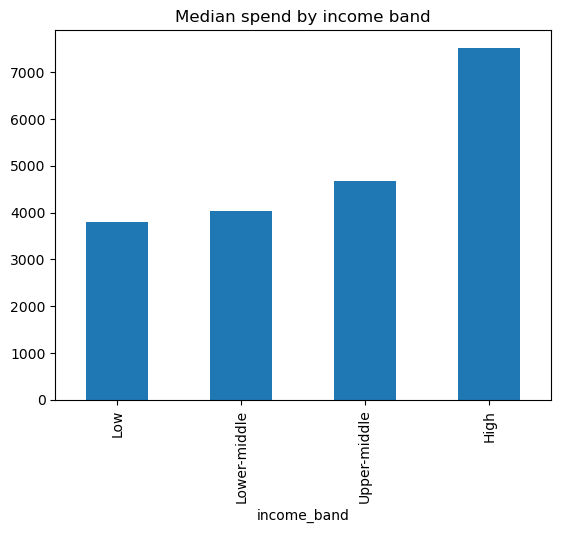

In [ ]:
hh["has_demo"] = hh.index.isin(demo["household_key"])
print(hh.groupby("has_demo")[["spend", "trips"]].median().round(1))

hd = hh.join(demo.set_index("household_key"), how="inner")
order = ["Low", "Lower-middle", "Upper-middle", "High"]
hd.groupby("income_band")["spend"].median().reindex(order).plot.bar(title="Median spend by income band")

- Households with demographics are much heavier shoppers (median spend $4,205 vs. $1,317; trips 125 vs. 50), so demographic data covers mostly engaged, targeted customers.
- Demographic results are framed as "among households with demographic data" and are not generalized to all customers.
- In modeling, demographics are used only in a subset model (801 households), alongside a full model without them.